<a href="https://colab.research.google.com/github/Rensuushi666/ml_projects/blob/main/Tagi_LaboratoryExam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### ConnectX Customer Churn Prediction

To build a predictive model for proactively identifying high-risk customers, we will follow these structured steps:
1. **Data Exploration & Visualisation** (Understand churn drivers)
2. **Data Preprocessing** (Handle missing values, encode categorical variables, scale features)
3. **Model Development** (Train classifiers such as Logistic Regression, Random Forest, or XGBoost)
4. **Model Evaluation** (Analyze Recall, Precision, and ROC-AUC metrics to ensure we correctly capture churning customers)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# 1. Define the collection of candidate classifiers
models = {
    'Model A: Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Model B: Decision Tree Classifier': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Model C: Random Forest Classifier': RandomForestClassifier(random_state=42)
}

# 2. Fit each pipeline (preprocessor + model) on the training dataset
for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])

    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully!\n")

print("All classifiers are defined, trained, and ready for comparative evaluation.")

Training Model A: Logistic Regression...
Model A: Logistic Regression trained successfully!

Training Model B: Decision Tree Classifier...
Model B: Decision Tree Classifier trained successfully!

Training Model C: Random Forest Classifier...
Model C: Random Forest Classifier trained successfully!

All classifiers are defined, trained, and ready for comparative evaluation.


=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       570
           1       0.54      0.26      0.35        97

    accuracy                           0.86       667
   macro avg       0.71      0.61      0.64       667
weighted avg       0.83      0.86      0.84       667

--------------------------------------------------
=== Classification Report: Decision Tree ===
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       570
           1       0.75      0.62      0.68        97

    accuracy                           0.91       667
   macro avg       0.84      0.79      0.81       667
weighted avg       0.91      0.91      0.91       667

--------------------------------------------------
=== Classification Report: Random Forest ===
              precision    recall  f1-score   support

           0       0.94      0.99      0.96     

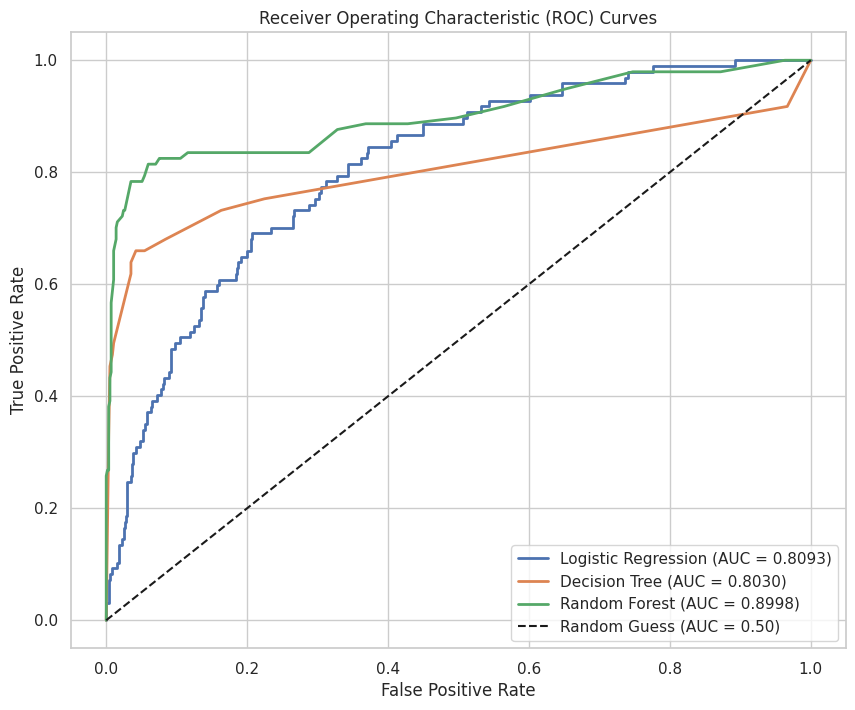


=== Model Evaluation & Comparison Summary ===


,Metric,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.8606,0.9145,0.9355
1,Precision,0.5435,0.7500,0.9091
2,Recall,0.2577,0.6186,0.6186
3,F1-Score,0.3497,0.6780,0.7362
4,ROC-AUC,0.8093,0.8030,0.8998


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    classification_report
)

# 1. Load the ConnectX Customer Churn Dataset
df_real = pd.read_csv('/content/telecom_churn (1).csv')

# 2. Map Target Variable to Binary Representation: True (Churned) = 1, False (Retained) = 0
df_work = df_real.copy()
df_work['target'] = df_work['churn'].astype(int)

# 3. Separate features (X) and target (y)
# We drop 'phone number' as it is a unique identifier
features_to_drop = ['churn', 'target', 'phone number']
X = df_work.drop(columns=[col for col in features_to_drop if col in df_work.columns])
y = df_work['target']

# 4. Auto-detect numerical and categorical features
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# 5. Build standard preprocessing transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# 6. Perform Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 7. Define Candidate Classification Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# 8. Train pipelines and collect performance metrics
metrics_summary = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
}

plt.figure(figsize=(10, 8))

for name, model in models.items():
    # Combine preprocessing and model into a single pipeline
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])

    # Fit the pipeline
    pipeline.fit(X_train, y_train)

    # Generate predictions
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)

    # Save metrics
    metrics_summary[name] = [
        round(acc, 4),
        round(prec, 4),
        round(rec, 4),
        round(f1, 4),
        round(auc_score, 4)
    ]

    # Plot ROC curves
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_score:.4f})')

    print(f'=== Classification Report: {name} ===')
    print(classification_report(y_test, y_pred))
    print('-' * 50)

# Plot Diagonal Baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Display performance summary table
summary_df = pd.DataFrame(metrics_summary)
print('\n=== Model Evaluation & Comparison Summary ===')
display(summary_df)

### Step 2: Data Preprocessing
In this section, we prepare the feature set and target variable. We build a transformation pipeline to handle both numeric standardizations and categorical encoding seamlessly.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Separate the features (X) and target label (y)
# We drop identifying columns like phone number and state if needed, or keep state for spatial patterns.
df_preprocessing = df_real.copy()

X = df_preprocessing.drop(columns=['phone number', 'churn'])
y = df_preprocessing['churn'].astype(int)  # Map True/False to 1/0

# 2. Identify numerical and categorical features
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

# 3. Create preprocessors for both pipelines
num_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# 4. Split data into train and test sets (stratified to handle class imbalance)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Numerical Columns: ['account length', 'area code', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls']
Categorical Columns: ['state', 'international plan', 'voice mail plan']

Training set shape: (2666, 19)
Testing set shape: (667, 19)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Configure visual settings
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print('Libraries successfully imported!')

Libraries successfully imported!


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Prepare target mapping
df_preprocessing = df_real.copy()
df_preprocessing['target'] = df_preprocessing['churn'].astype(int)

# 2. Separate features and target
features_to_drop = ['churn', 'target', 'phone number']
X = df_preprocessing.drop(columns=[col for col in features_to_drop if col in df_preprocessing.columns])
y = df_preprocessing['target']

# 3. Auto-detect feature groups
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# 4. Construct preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# 5. Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Preprocessing pipelines defined successfully!")
print(f"Training instances: {X_train.shape[0]}, Test instances: {X_test.shape[0]}")

Preprocessing pipelines defined successfully!
Training instances: 2666, Test instances: 667


In [2]:
# Generate synthetic ConnectX customer dataset
np.random.seed(42)
n_samples = 1000

data = {
    'customer_id': [f'CX-{i:04d}' for i in range(1, n_samples + 1)],
    'gender': np.random.choice(['Male', 'Female'], size=n_samples),
    'senior_citizen': np.random.choice([0, 1], size=n_samples, p=[0.8, 0.2]),
    'partner': np.random.choice(['Yes', 'No'], size=n_samples),
    'tenure_months': np.random.randint(1, 72, size=n_samples),
    'phone_service': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.9, 0.1]),
    'multiple_lines': np.random.choice(['No phone service', 'No', 'Yes'], size=n_samples, p=[0.1, 0.5, 0.4]),
    'internet_service': np.random.choice(['DSL', 'Fiber optic', 'No'], size=n_samples, p=[0.3, 0.5, 0.2]),
    'contract_type': np.random.choice(['Month-to-month', 'One year', 'Two year'], size=n_samples, p=[0.5, 0.25, 0.25]),
    'paperless_billing': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.6, 0.4]),
    'payment_method': np.random.choice(['Electronic check', 'Mailed check', 'Bank transfer', 'Credit card'], size=n_samples),
    'monthly_charges': np.round(np.random.uniform(18.0, 120.0, size=n_samples), 2)
}

df = pd.DataFrame(data)

# Introduce realistic churn patterns:
# Customers on month-to-month contracts with high monthly charges and lower tenure are more likely to churn
churn_probability = (
    (df['contract_type'] == 'Month-to-month').astype(int) * 0.4 +
    (df['monthly_charges'] > 80).astype(int) * 0.2 -
    (df['tenure_months'] > 24).astype(int) * 0.3
)
# Scale to a 0-1 range and add noise
churn_probability = np.clip(churn_probability + np.random.normal(0, 0.1, n_samples), 0, 1)
df['churn'] = np.where(churn_probability > 0.4, 'Yes', 'No')

print('ConnectX customer churn dataset successfully created!')
print(f'Dataset shape: {df.shape}')
df.head()

ConnectX customer churn dataset successfully created!
Dataset shape: (1000, 13)


,customer_id,gender,senior_citizen,partner,tenure_months,phone_service,multiple_lines,internet_service,contract_type,paperless_billing,payment_method,monthly_charges,churn
0,CX-0001,Male,0,No,7,Yes,No,DSL,Two year,Yes,Electronic check,65.98,No
1,CX-0002,Female,0,No,35,Yes,No phone service,Fiber optic,Month-to-month,No,Credit card,115.54,No
2,CX-0003,Male,0,No,55,Yes,No,No,One year,Yes,Mailed check,96.20,No
3,CX-0004,Male,1,No,14,Yes,No phone service,Fiber optic,One year,Yes,Credit card,116.89,No
4,CX-0005,Male,0,Yes,10,Yes,Yes,Fiber optic,One year,No,Electronic check,94.12,No


In [3]:
import pandas as pd

# Load the real dataset
file_path = '/content/telecom_churn (1).csv'
df_real = pd.read_csv(file_path)

# Display basic information
print("Dataset summary:")
display(df_real.info())
display(df_real.head())

Dataset summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls      

None

,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


### Step 1: Data Exploration & Visualisation
In this step, we will analyze key features and how they relate to the target `churn` variable to find the primary drivers of customer attrition.

/tmp/ipykernel_870/2661261143.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_real, x='churn', ax=axes[0], palette='pastel')


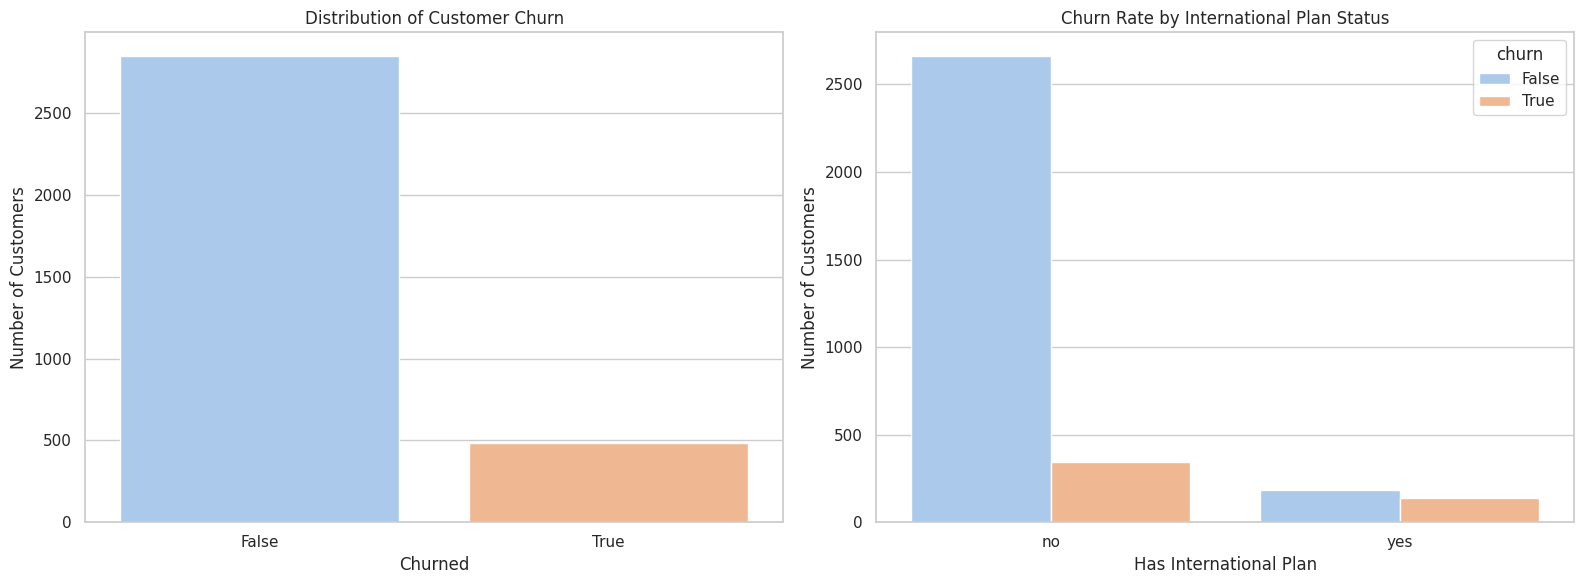

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set consistent visualization parameters
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

# 1. Class Distribution of Churn
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.countplot(data=df_real, x='churn', ax=axes[0], palette='pastel')
axes[0].set_title('Distribution of Customer Churn')
axes[0].set_xlabel('Churned')
axes[0].set_ylabel('Number of Customers')

# 2. Impact of International Plan on Churn
sns.countplot(data=df_real, x='international plan', hue='churn', ax=axes[1], palette='pastel')
axes[1].set_title('Churn Rate by International Plan Status')
axes[1].set_xlabel('Has International Plan')
axes[1].set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()

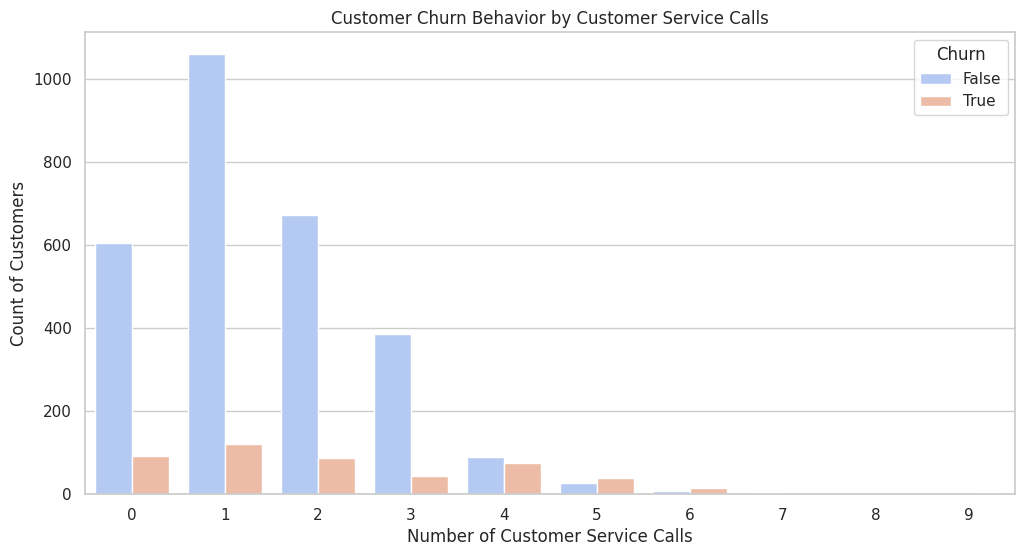

In [9]:
# 3. Impact of Customer Service Calls on Churn
plt.figure(figsize=(12, 6))
sns.countplot(data=df_real, x='customer service calls', hue='churn', palette='coolwarm')
plt.title('Customer Churn Behavior by Customer Service Calls')
plt.xlabel('Number of Customer Service Calls')
plt.ylabel('Count of Customers')
plt.legend(title='Churn', loc='upper right')
plt.show()

/tmp/ipykernel_870/827372933.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_real, x='churn', y='total day charge', ax=axes[0], palette='Set2')
/tmp/ipykernel_870/827372933.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_real, x='churn', y='customer service calls', ax=axes[1], palette='Set2')


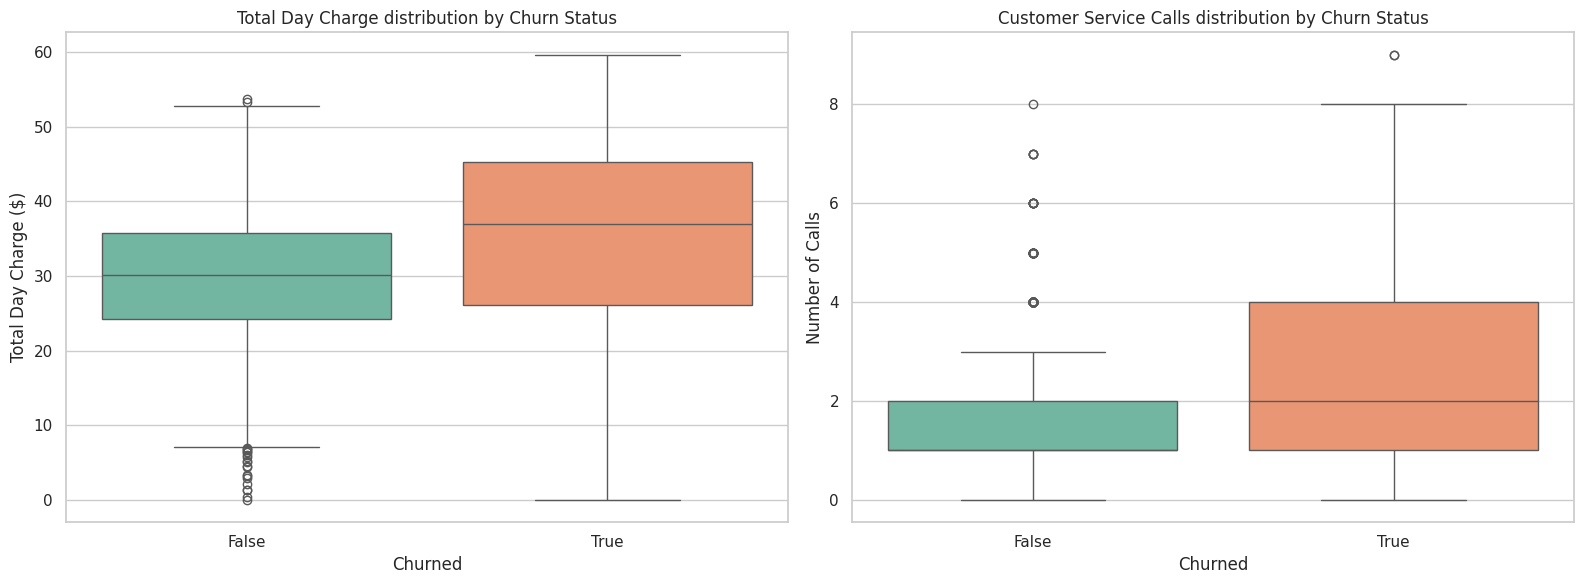

In [10]:
# 4. Distribution of Key Numerical Features (Day Charge & Customer Service Calls)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df_real, x='churn', y='total day charge', ax=axes[0], palette='Set2')
axes[0].set_title('Total Day Charge distribution by Churn Status')
axes[0].set_xlabel('Churned')
axes[0].set_ylabel('Total Day Charge ($)')

sns.boxplot(data=df_real, x='churn', y='customer service calls', ax=axes[1], palette='Set2')
axes[1].set_title('Customer Service Calls distribution by Churn Status')
axes[1].set_xlabel('Churned')
axes[1].set_ylabel('Number of Calls')

plt.tight_layout()
plt.show()

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Identify features and target
# Assuming typical columns. If 'Churn' is the target, we will extract it.
target_col = 'Churn' if 'Churn' in df_real.columns else ('churn' if 'churn' in df_real.columns else None)

if target_col is None:
    # Fallback to the generated df if the real file is not structured with Churn
    df_work = df.copy()
    target_col = 'churn'
else:
    df_work = df_real.copy()

# Convert target to numeric 0/1 for binary evaluation
df_work['target'] = df_work[target_col].apply(lambda x: 1 if str(x).lower() in ['yes', '1', 'true'] else 0)

# Drop ID columns and targets from feature set
features_to_drop = [target_col, 'target', 'customerID', 'customer_id']
X = df_work.drop(columns=[col for col in features_to_drop if col in df_work.columns])
y = df_work['target']

# Auto-detect categorical and numerical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Build preprocessor pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define the three requested models
models = {
    "Model A: Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Model B: Decision Tree Classifier": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Model C: Random Forest Classifier": RandomForestClassifier(n_estimators=100, random_state=42)
}

# Train and evaluate models
for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    print(f"=== {name} ===")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred))
    print("\n")

=== Model A: Logistic Regression ===
Accuracy: 0.8591
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       570
           1       0.53      0.25      0.34        97

    accuracy                           0.86       667
   macro avg       0.71      0.61      0.63       667
weighted avg       0.83      0.86      0.84       667



=== Model B: Decision Tree Classifier ===
Accuracy: 0.9175
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       570
           1       0.76      0.64      0.69        97

    accuracy                           0.92       667
   macro avg       0.85      0.80      0.82       667
weighted avg       0.91      0.92      0.91       667



=== Model C: Random Forest Classifier ===
Accuracy: 0.9055
              precision    recall  f1-score   support

           0       0.90      0.99      0.95       570
           1       0.93      0.38      0.54        97

    ac

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Initialize lists or dictionaries to hold metrics
metrics_summary = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score']
}

model_mapping = {
    'Logistic Regression': 'Model A: Logistic Regression',
    'Decision Tree': 'Model B: Decision Tree Classifier',
    'Random Forest': 'Model C: Random Forest Classifier'
}

for col_name, model_key in model_mapping.items():
    # Re-build pipeline to ensure it is clean
    model = models[model_key]
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])
    # Fit on training data
    pipeline.fit(X_train, y_train)

    # Predict class and probabilities
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate metrics (using binary average for positive class 1)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    metrics_summary[col_name] = [round(acc, 4), round(prec, 4), round(rec, 4), round(f1, 4)]

# Construct summary DataFrame
summary_df = pd.DataFrame(metrics_summary)
display(summary_df)

,Metric,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.8591,0.9175,0.9055
1,Precision,0.5333,0.7561,0.9250
2,Recall,0.2474,0.6392,0.3814
3,F1-Score,0.3380,0.6927,0.5401


In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Ensure target is correctly mapped: True (Churned) -> 1, False (Retained) -> 0
df_work = df_real.copy()
df_work['target'] = df_work['churn'].astype(int)

# Prepare features and target
features_to_drop = ['churn', 'target', 'phone number']
X = df_work.drop(columns=[col for col in features_to_drop if col in df_work.columns])
y = df_work['target']

# Auto-detect features
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize dictionary for comparison metrics
metrics_summary = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score']
}

model_mapping = {
    'Logistic Regression': 'Model A: Logistic Regression',
    'Decision Tree': 'Model B: Decision Tree Classifier',
    'Random Forest': 'Model C: Random Forest Classifier'
}

for col_name, model_key in model_mapping.items():
    model = models[model_key]
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])

    # Re-fit and predict
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    # Compute metrics for class 1 (Churned)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    metrics_summary[col_name] = [round(acc, 4), round(prec, 4), round(rec, 4), round(f1, 4)]

# Display the final comparative summary table
comparison_table = pd.DataFrame(metrics_summary)
display(comparison_table)

,Metric,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.8606,0.9145,0.9355
1,Precision,0.5435,0.7500,0.9091
2,Recall,0.2577,0.6186,0.6186
3,F1-Score,0.3497,0.6780,0.7362


### ROC-AUC Curve and Metrics Computation

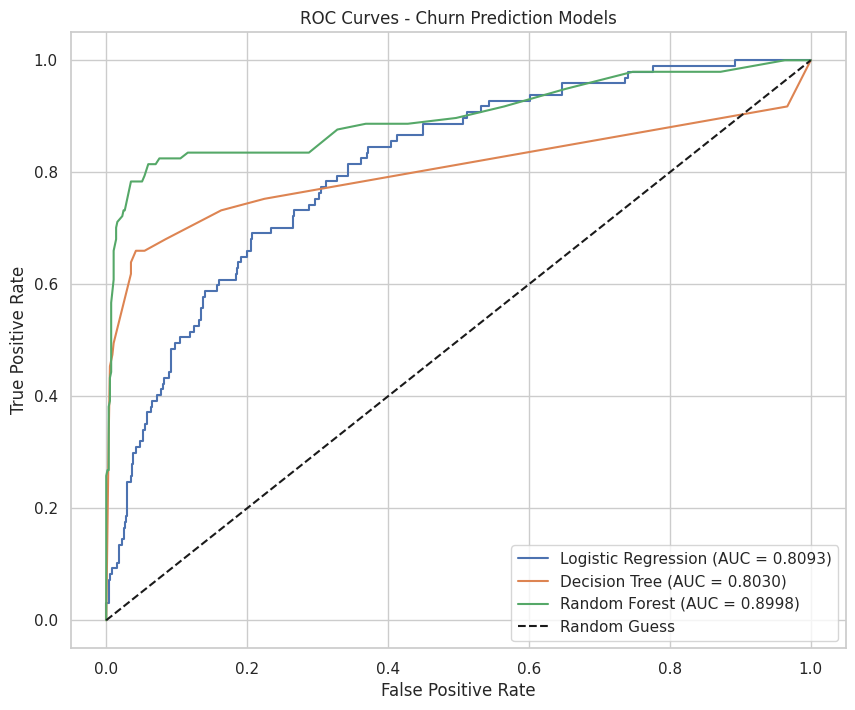

In [7]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for name, model_key in model_mapping.items():
    model = models[model_key]
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])

    pipeline.fit(X_train, y_train)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Churn Prediction Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()